# E0.3d — BTC Bollinger parameter surfaces

**Aim:** keep `(20, 2.0)` benchmark and compare 77 `(window, sigma)` pairs at 4H / 1H / 15m / 5m. This is **descriptive screening**, not trading optimization or proof of prediction.

Metrics: previous-band close containment; width; crossings/day; movement-following via post-impulse SMA response; each reported separately. **Note:** containment and response metrics do *not* share an automatic weighting. Historical impulse markers are for retrospective diagnostics only.

**Data:** use the verified 5-minute BTC OHLCV dataframe indexed by candle **open UTC**. Include data prior to START for warmup. The research period is 2025; do not call it a holdout.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from walk_states import bollinger_from_5m, detect_walk_states
from e03_analysis import (align_to_5m, occupancy, next_walk_probabilities,
                          cross_overlap, conditional_lift, plot_pair)

import requests
from pathlib import Path
import json

START, END = "2025-01-01", "2026-01-01"
TIMEFRAMES = {"4H":"4h", "1H":"1h", "15m":"15min", "5m":"5min"}
PARAMS = dict(near=0.15, confirm_bars=3, exit_bars=2, slope_bars=3)

NOV_START = "2025-11-13"
NOV_END = "2025-11-23"

CONFIGS = {"1D":"1D", "1H":"1h", "15m":"15min", "5m":"5min"}
WINDOW = 20
NEAR = 0.15
CONFIRM_BARS = 3
EXIT_BARS = 2
SLOPE_BARS = 3

REPO = Path("/media/ata/Data/personal/binbot")
DATA_DIR = REPO / "research" / "sentiment_price" / "data"
CACHE_DIR = DATA_DIR / "btcusdt_5m_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Warm-up before 2025 and a buffer for forward-return labels.
START = pd.Timestamp("2024-12-30", tz="UTC")
END = pd.Timestamp("2026-01-02", tz="UTC")  # exclusive

STEP_MS = 5 * 60 * 1000
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)

print("Expected candles:", (END_MS - START_MS) // STEP_MS)

# Paste the verified 5m OHLCV loader from 02_price_features.ipynb or E03 here.
# TODO: paste verified 5-minute data loading code from 02_price_features.ipynb
all_candles = []
cursor = START_MS

with requests.Session() as session:
    while cursor < END_MS:
        batch_end = min(cursor + 1000 * STEP_MS, END_MS)
        cache_file = CACHE_DIR / f"{cursor}_{batch_end}.json"

        if cache_file.exists():
            batch = json.loads(cache_file.read_text())
        else:
            response = session.get(
                "https://api.binance.com/api/v3/klines",
                params={
                    "symbol": "BTCUSDT",
                    "interval": "5m",
                    "timeZone": "0",
                    "startTime": cursor,
                    "endTime": batch_end - 1,
                    "limit": 1000,
                },
                timeout=30,
            )
            response.raise_for_status()
            batch = response.json()

        if not isinstance(batch, list) or not batch:
            raise ValueError(f"Unexpected response at {cursor}: {batch}")

        # Require every expected candle; do not silently fill gaps.
        expected_opens = list(range(cursor, batch_end, STEP_MS))
        actual_opens = [int(row[0]) for row in batch]

        if actual_opens != expected_opens:
            raise ValueError(
                f"Missing, duplicate or unexpected candles in batch {cursor}"
            )

        if not cache_file.exists():
            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(json.dumps(batch))
            temporary.replace(cache_file)
            time.sleep(0.2)

        all_candles.extend(batch)
        cursor = batch_end

        print(
            f"\rLoaded {len(all_candles):,} candles",
            end="",
            flush=True,
        )

print("\nDownload/cache loading complete.")
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trade_count",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(all_candles, columns=columns)

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric = [
    "open", "high", "low", "close", "volume", "quote_volume",
    "trade_count", "taker_buy_volume", "taker_buy_quote_volume",
]
bars[numeric] = bars[numeric].apply(pd.to_numeric, errors="raise")
bars = bars.set_index("open_time").sort_index()

expected_index = pd.date_range(
    START, END - pd.Timedelta(minutes=5), freq="5min"
)

assert bars.index.is_unique
assert bars.index.equals(expected_index), "Unexpected candle coverage"
assert bars[numeric].notna().all().all()
assert (bars[["open", "high", "low", "close"]] > 0).all().all()
assert (bars["low"] <= bars[["open", "close"]].min(axis=1)).all()
assert (bars["high"] >= bars[["open", "close"]].max(axis=1)).all()
assert (bars["volume"] >= 0).all()
assert "bars" in globals(), "Load your existing 5m OHLCV dataframe as bars first"
assert "bars" in globals(), "First load your verified 5-minute OHLCV dataframe as `bars`."
assert {"open","high","low","close","volume"}.issubset(bars.columns)
print('Rows:',len(bars),'Range:',bars.index.min(),bars.index.max())

Expected candles: 105984
Loaded 6,000 candles

Loaded 105,984 candles
Download/cache loading complete.
Rows: 105984 Range: 2024-12-30 00:00:00+00:00 2026-01-01 23:55:00+00:00


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from e03d_surface import surface, compare_shared, plot_heatmap, WINDOWS, SIGMAS
from walk_states import bollinger_from_5m

START, END = "2025-01-01", "2026-01-01"
TF = {"4H":"4h", "1H":"1h", "15m":"15min", "5m":"5min"}

# TODO: paste ONLY the verified 5-minute OHLCV loading code here.
# bars = ...  # UTC open-time index, columns open/high/low/close/volume
assert 'bars' in globals(), 'Load verified 5-minute bars as bars before proceeding'


## Common analysis population
To compare all window configurations fairly, all metrics are calculated on a **shared fully warmed-up start**. The 50-period prior band is available at the start, if your loader includes enough pre-start data. We build the analysis starting slightly before the year and score only from START. The surface function shifts bands by one bar for containment and crossings.

In [4]:
runs = {}
for label, freq in TF.items():
    # Window 50 in 4H requires ~8.3 days of 5m prehistory.
    early = pd.Timestamp(START, tz='UTC') - pd.Timedelta('15D')
    d = bollinger_from_5m(bars, early, END, resolution=freq, window=2, num_std=2.0)
    # Need full lookback for rolling N, hence build on this warmup slice.
    # For fair metrics, retain sufficient history and then select identical score dates.
    metric = surface(d, windows=WINDOWS, sigmas=SIGMAS)
    # Better: recompute each row on a shared evaluation slice below.
    runs[label] = dict(data=d, raw_surface=metric)
    print(label, len(d), 'candles')


4H 2202 candles
1H 8808 candles
15m 35232 candles
5m 105696 candles


### Restrict metrics to an identical scoring interval
The simple `surface()` aggregates all input rows, including its warm-up. For publication-quality results, **do not compare those raw aggregates**. The function below supplies pre-start price history yet filters the score population to the common period. This is implemented by adding a `score_start` argument in the module; if working from an older module, replace it with this release.

In [5]:
# Fixed evaluation dates: 2025-01-03 through 2025-12-31, avoiding prehistory count effects
SCORE_START = "2025-01-03"
surfaces={}
for label, run in runs.items():
    d=run['data']
    s=surface(d, windows=WINDOWS, sigmas=SIGMAS, score_start=SCORE_START)
    surfaces[label]=s
    benchmark=s[(s.window==20) & (s.sigma==2.0)]
    print(label, 'baseline')
    display(benchmark[['window','sigma','valid_bars','containment','median_width_pct','crossing_per_day','response_alignment']])


4H baseline


,window,sigma,valid_bars,containment,median_width_pct,crossing_per_day,response_alignment
45,20,2.0,2179,0.828362,4.784066,0.48738,0.494681


1H baseline


,window,sigma,valid_bars,containment,median_width_pct,crossing_per_day,response_alignment
45,20,2.0,8713,0.815792,2.169794,2.333066,0.570997


15m baseline


,window,sigma,valid_bars,containment,median_width_pct,crossing_per_day,response_alignment
45,20,2.0,34849,0.823983,0.980769,9.611294,0.560374


5m baseline


,window,sigma,valid_bars,containment,median_width_pct,crossing_per_day,response_alignment
45,20,2.0,104545,0.826065,0.561809,29.140217,0.562794


## Parameter surfaces
The highest containment is usually achieved by wider bands. That's not necessarily useful. Compare all metrics jointly and don't select a pair by one heatmap.

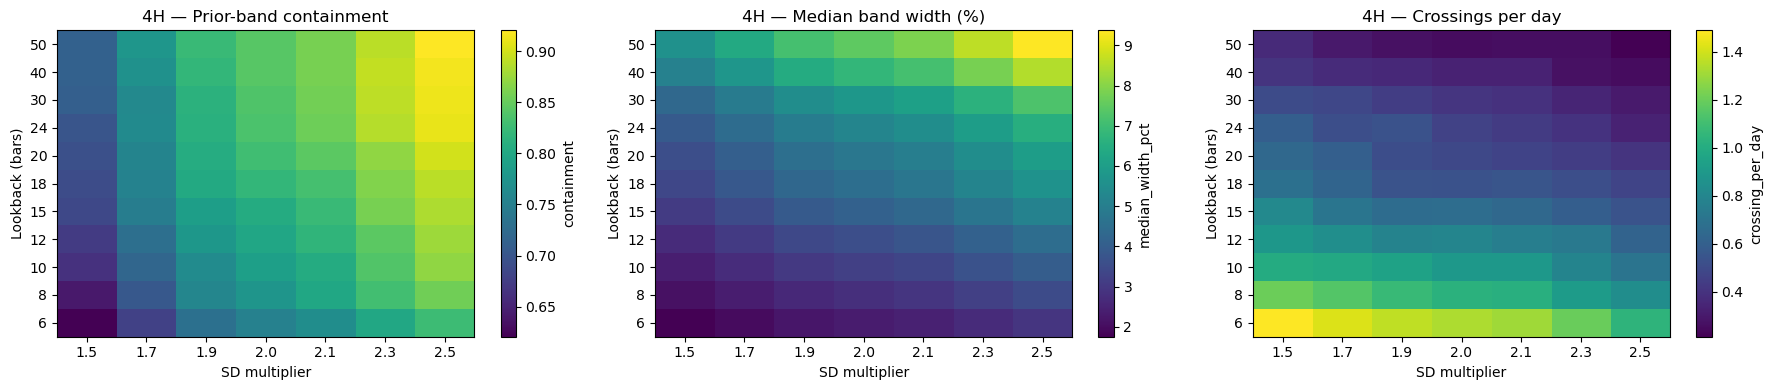

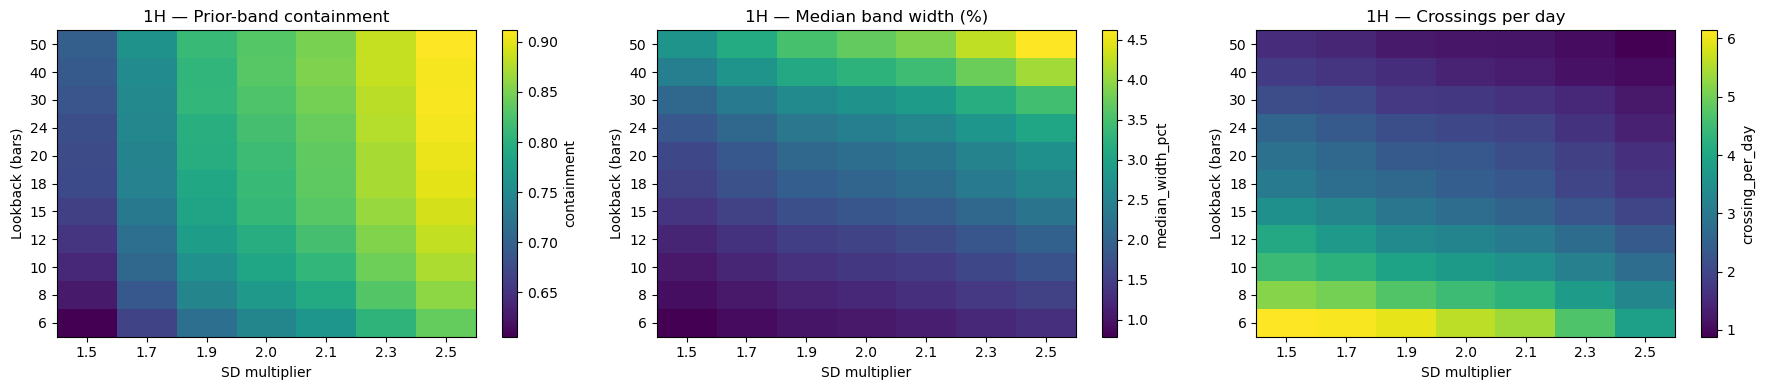

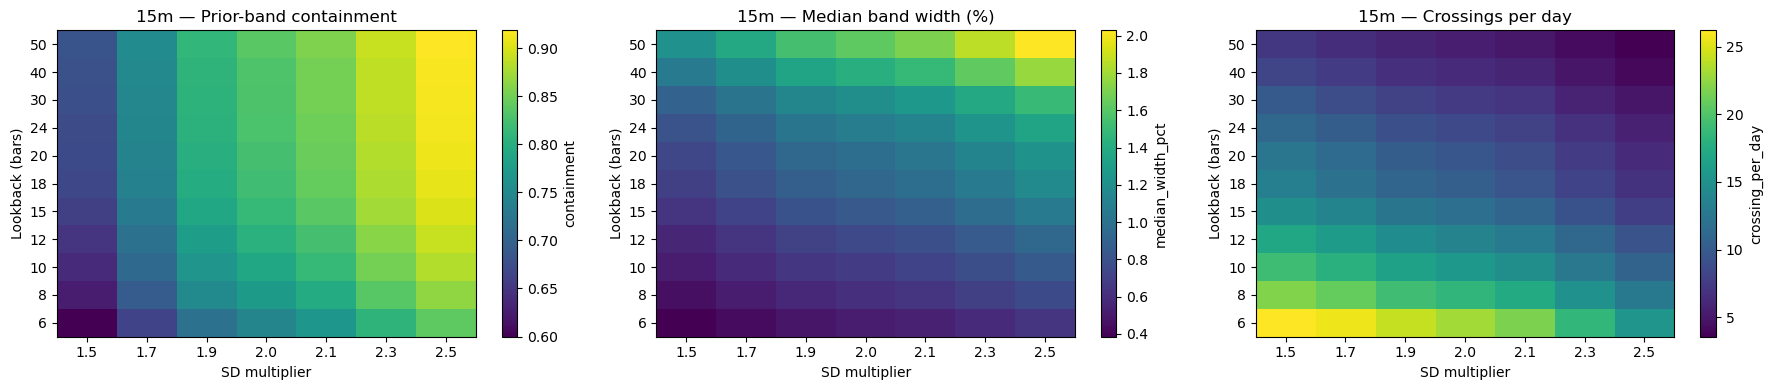

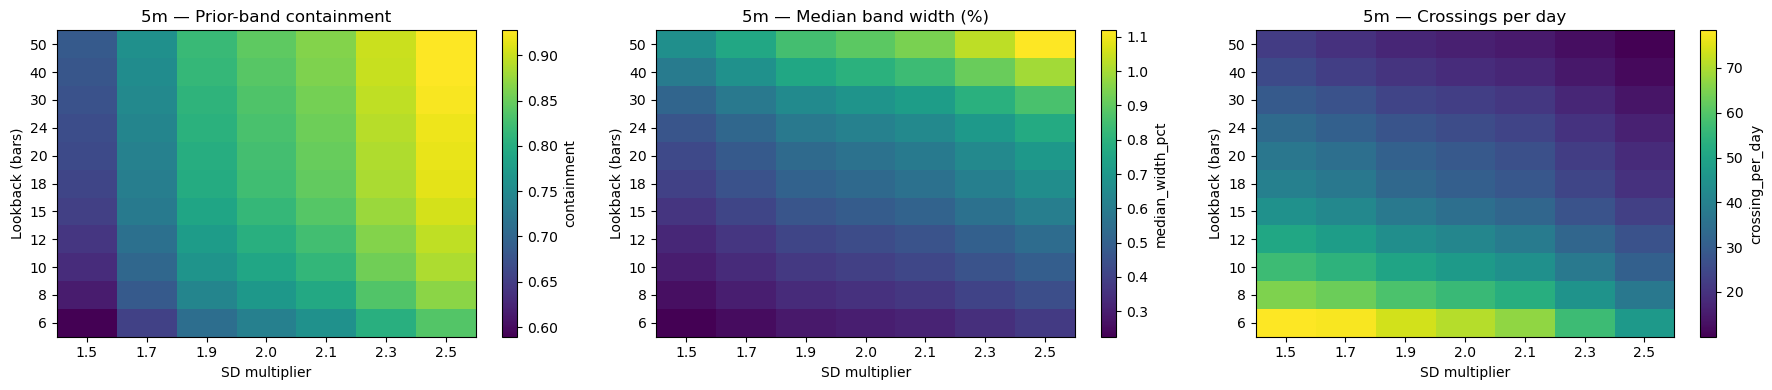

In [6]:
for tf in TF:
    d=surfaces[tf]
    fig,axes=plt.subplots(1,3,figsize=(18,4))
    for ax,(col,title) in zip(axes,[('containment','Prior-band containment'),('median_width_pct','Median band width (%)'),('crossing_per_day','Crossings per day')]):
        plot_heatmap(d,col,title=f'{tf} — {title}',ax=ax)
    plt.tight_layout();plt.show()


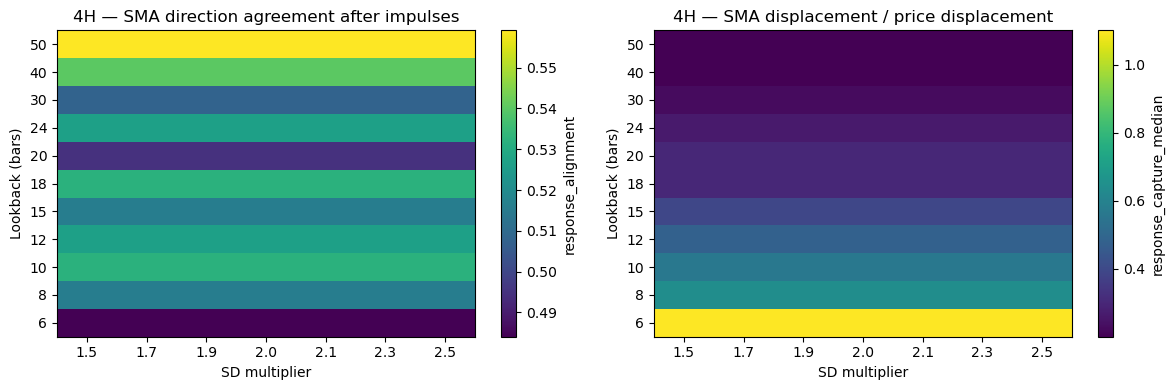

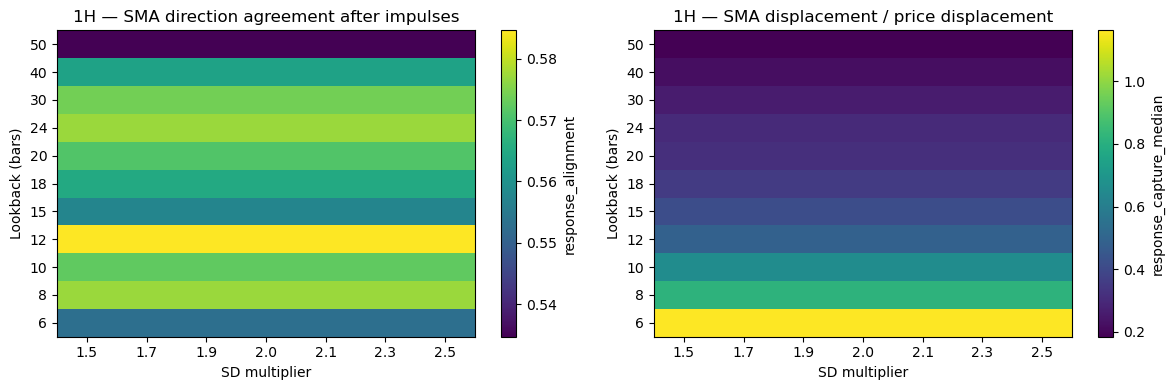

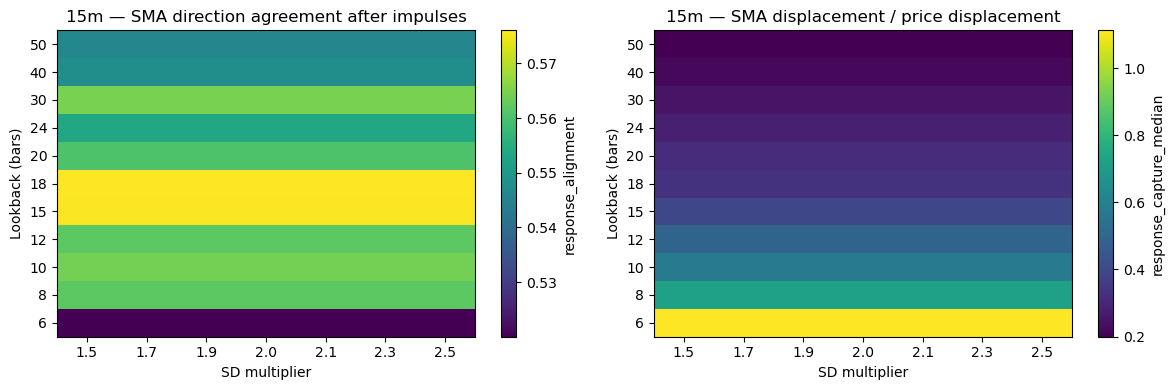

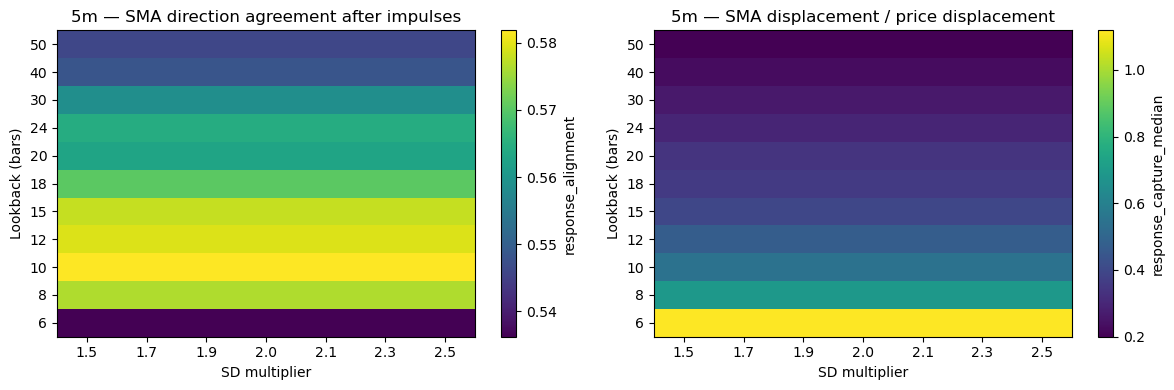

In [7]:
for tf in TF:
    d=surfaces[tf]
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    plot_heatmap(d,'response_alignment',f'{tf} — SMA direction agreement after impulses',ax=axes[0])
    plot_heatmap(d,'response_capture_median',f'{tf} — SMA displacement / price displacement',ax=axes[1])
    plt.tight_layout();plt.show()


## One common pair, or separate pairs?
The helper below ranks only for a **screening target containment** (default 90%) and secondary band width, NOT breakout Pd or trading PnL. Its answer is merely a starting region. Compare the per-timeframe and shared choices; do not treat the returned choice as final.

In [8]:
best_each,shared,all_scores=compare_shared(surfaces,target=0.90)
display(best_each[['tf','window','sigma','containment','median_width_pct','crossing_per_day','rank']])
display(shared)


,tf,window,sigma,containment,median_width_pct,crossing_per_day,rank
188,15m,15,2.5,0.902293,1.055501,7.801429,1.50
118,1H,18,2.5,0.899575,2.553208,1.694020,1.55
48,4H,20,2.5,0.899495,5.980083,0.402019,1.61
306,5m,50,2.3,0.900473,1.029392,12.572882,1.76


,window,sigma,mean_rank,worst_rank
41,18,2.5,4.5675,8.57


## Next validation gate
1. Add true independent reference-event detection rate, duplicate alarms and latency **using E0.3c's existing matching procedure**, with its event population frozen across `(N,k)` and with one-to-one matching.
2. Include time-block uncertainty and separate selection/test periods.
3. Only after conventional bands have a measured containment/latency frontier: compare EMA bands, EWMA-volatility bands and a two-state Kalman location/velocity + innovation-variance envelope. State-space is a *challenger*, not a presumed winner. A moving average is a linear filter, but the sliding standard deviation makes the full Bollinger envelope nonlinear already.
